# Test de Hipótesis: de $t$ a $\chi^2$ — Teoría y Ejemplos en Python

Este notebook desarrolla, paso a paso y con código, el marco de test de hipótesis basados en cocientes de verosimilitud:

1. Marco general del test de hipótesis: $H_0$, $H_1$, el estadístico $t$, la pdf $g(t|H_0)$
2. Errores tipo I / tipo II y el **lema de Neyman–Pearson**
3. El **teorema de Wilks**: de dónde sale la $\chi^2$
4. Cómo construir $g(t|H_0)$ con **toys (Monte Carlo)** paso a paso
5. La conexión $t \leftrightarrow \chi^2 \leftrightarrow \alpha \leftrightarrow$ p-valor
6. Ejemplos progresivos:
   - Caso exacto (Gaussiana, $\sigma$ conocida)
   - Selección de orden de un modelo anidado (análogo a la selección de grado de un polinomio de Bernstein)
   - Caso con **frontera** en el espacio de parámetros (por qué Wilks puede fallar — relevante para coeficientes de Bernstein restringidos a ser positivos)
   - Hipótesis **no anidadas** sin fórmula cerrada (Gaussiana vs. t-Student)
   - Las "dos montañitas": $g(t|H_0)$ vs $g'(t|H_1)$, $\alpha$, $\beta$, potencia
7. Ejercicios, de fácil a difícil

> Nota: los ejemplos usan modelos genéricos (Gaussianas, polinomios) para que corran rápido y se entiendan bien. La mecánica es *idéntica* a la de un análisis con NLL binomial y polinomios de Bernstein, común en ajustes de eficiencia en física de partículas — donde cambian los nombres, se señala explícitamente.

## 1. Marco general

Partimos de dos hipótesis:

- $H_0$: hipótesis nula (el modelo "simple" o de referencia)
- $H_1$ (o $H'$): hipótesis alternativa

Construimos un **estadístico de prueba** $t(x)$ a partir de los datos $x$. La elección más común (y la óptima, según veremos con Neyman–Pearson) es el **cociente de verosimilitudes**:

$$ t(x) = -2\ln\left[\frac{L(x|H_0)}{L(x|H_1)}\right] = -2\big[\ln L(x|H_0) - \ln L(x|H_1)\big] $$

Puntos clave:

- $t$ es una **función fija** de los datos — la fórmula usa $H_0$ y $H_1$ como "marcas de referencia" ya fijadas de antemano.
- La **aleatoriedad de $t$ viene solo de $x$**. Si generas datos bajo $H_0$ muchas veces y evalúas $t(x)$ en cada uno, obtienes una distribución: esa es $g(t|H_0)$.
- Formalmente, $g$ es la distribución "empujada" (*pushforward*) de la pdf de los datos bajo $H_0$:

$$ g(t|H_0)\,dt = \int \delta\big(t - t(x)\big)\, P(x|H_0)\, dx $$

- $t_{obs}$ se calcula **una sola vez**, con los datos reales.
- El **p-valor** es la probabilidad, bajo $H_0$, de obtener un $t$ tan extremo o más que el observado:

$$ p = P(t \ge t_{obs} \mid H_0) = \int_{t_{obs}}^{\infty} g(t|H_0)\, dt $$

- $\alpha$ es el **umbral que se elige** de antemano (la tolerancia al error tipo I). $t_{crítico}$ es el valor de $t$ tal que:

$$ \alpha = \int_{t_{crítico}}^{\infty} g(t|H_0)\, dt \quad\Longleftrightarrow\quad t_{crítico} = g^{-1}(1-\alpha) $$

Rechazas $H_0$ si $t_{obs} > t_{crítico}$, lo cual es exactamente equivalente a rechazar si $p < \alpha$.

**Dos formas de obtener $g(t|H_0)$:**

| Método | Cómo | Cuándo |
|---|---|---|
| **Toys / MC** | Generas datos sintéticos bajo $H_0$ miles de veces, calculas $t$ en cada uno, el histograma **es** $g(t|H_0)$ | Siempre funciona, pero cuesta cómputo |
| **Fórmula asintótica (Wilks)** | Si $H_0 \subset H_1$ (anidadas) y se cumplen condiciones de regularidad, $g(t|H_0) \to \chi^2_k$ | Rápido, pero solo válido bajo ciertas condiciones |

## 2. Errores tipo I, tipo II, y el lema de Neyman–Pearson

Con un corte $t_{crítico}$ fijo, hay cuatro posibles desenlaces. Los dos "malos":

- **Error tipo I** ($\alpha$): rechazar $H_0$ cuando en realidad $H_0$ era verdadera (falsa alarma).
  $$\alpha = P(t \ge t_{crítico} \mid H_0)$$
- **Error tipo II** ($\beta$): no rechazar $H_0$ cuando en realidad $H_1$ era verdadera (no detectar algo real).
  $$\beta = P(t < t_{crítico} \mid H_1)$$
- **Potencia** del test: $1-\beta$ = probabilidad de detectar correctamente $H_1$ cuando es verdadera.

Moviendo $t_{crítico}$, $\alpha$ y $\beta$ se mueven en direcciones opuestas — es un trade-off, no puedes bajar ambos con un solo corte.

### Lema de Neyman–Pearson

Para comparar dos hipótesis **simples** (parámetros completamente especificados en ambas), el lema de Neyman–Pearson dice que, **de entre todos los posibles tests con un $\alpha$ fijo, el que maximiza la potencia (minimiza $\beta$) es exactamente el test basado en el cociente de verosimilitudes**:

$$ \Lambda(x) = \frac{L(x|H_0)}{L(x|H_1)} $$

rechazando $H_0$ cuando $\Lambda(x)$ es suficientemente pequeño (equivalentemente, cuando $t=-2\ln\Lambda$ es suficientemente grande). Esta es la razón *por la que* usamos $t$ construido como cociente de verosimilitudes y no cualquier otro estadístico: es demostrablemente el **más potente** (UMP, *uniformly most powerful*) para hipótesis simples. Para hipótesis compuestas (con parámetros libres, como casi siempre en la práctica) ya no hay una garantía UMP universal, pero el cociente de verosimilitud generalizado sigue siendo la elección estándar por sus buenas propiedades asintóticas (Wilks).

## 3. Teorema de Wilks: ¿de dónde sale la $\chi^2$?

**Enunciado (caso nested / anidado):** si $H_0$ es un caso particular de $H_1$ obtenido fijando $k$ de sus parámetros (modelos *anidados*), y se cumplen condiciones de regularidad (el óptimo no está en la frontera del espacio de parámetros, el tamaño de muestra es grande, el modelo es identificable), entonces, bajo $H_0$:

$$ t = -2\ln\left[\frac{L(\hat\theta_0)}{L(\hat\theta_1)}\right] \;\xrightarrow{\ n\to\infty\ }\; \chi^2_k $$

donde $\hat\theta_0,\hat\theta_1$ son los estimadores de máxima verosimilitud (MLE) bajo cada hipótesis, y $k$ = diferencia en número de parámetros libres.

**Idea de la demostración (heurística):**

1. Expandes $\ln L(\theta)$ en Taylor alrededor del MLE $\hat\theta$ (donde el gradiente es cero):
   $$ \ln L(\theta) \approx \ln L(\hat\theta) - \tfrac{1}{2}(\theta-\hat\theta)^T I(\hat\theta) (\theta-\hat\theta) $$
   con $I$ la matriz de información de Fisher.
2. El MLE es asintóticamente normal (teorema central del límite aplicado al score): $\hat\theta \sim \mathcal{N}(\theta_{true}, I^{-1})$.
3. Sustituyendo, $-2[\ln L(\theta_{true}) - \ln L(\hat\theta)] = (\hat\theta-\theta_{true})^T I (\hat\theta-\theta_{true})$.
4. Esa es una **forma cuadrática de un vector normal** con covarianza $I^{-1}$ — y por definición, eso es una suma de $k$ variables normales estándar al cuadrado, es decir, **una $\chi^2_k$**.

El $-2$ y el $\ln$ en la definición de $t$ **no son arbitrarios**: son exactamente lo que hace que la expansión de Taylor deje una forma cuadrática pura. Si se cambia la receta (otro factor, otro estadístico, modelos no anidados), se pierde esta garantía.

**Condición de regularidad importante:** si el/los parámetro(s) extra de $H_1$ tienen una **frontera física** bajo $H_0$ (ej. un coeficiente que debe ser $\ge 0$, y su valor verdadero bajo $H_0$ está justo en esa frontera), la demostración de arriba se rompe (el MLE ya no puede moverse simétricamente en ambas direcciones). En ese caso la distribución asintótica correcta es una **mezcla** de $\chi^2$ (resultado de Chernoff 1954, generalizado por Self & Liang 1987) — lo vas a ver en el Ejemplo 3, y es directamente relevante para coeficientes de Bernstein con restricción de positividad.

## 4. Código base

Imports y funciones que vamos a reutilizar en todos los ejemplos.

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def p_value_from_toys(t_obs, t_toys):
    '''p-valor empirico: fraccion de toys con t >= t_obs.'''
    return np.mean(np.asarray(t_toys) >= t_obs)


def t_crit_from_toys(t_toys, alpha):
    '''Percentil (1-alpha) de la muestra de toys -> t_critico empirico.'''
    return np.quantile(t_toys, 1 - alpha)


def plot_g_vs_chi2(t_toys, dof, t_obs=None, alpha=0.05, title="", bins=60):
    '''Histograma de toys EN CONTEOS (montañita explicita, no densidad), con la
    region de rechazo marcada segun alpha, t_critico, y la decision (rechaza/no
    rechaza H0) segun donde cae t_obs. La chi2_dof (Wilks) se muestra de referencia,
    escalada a las mismas unidades (conteos por bin).'''
    fig, ax = plt.subplots()
    tmax = max(np.max(t_toys), (t_obs or 0)) * 1.05
    counts, edges = np.histogram(t_toys, bins=bins, range=(0, tmax))
    bin_width = edges[1] - edges[0]
    centers = 0.5 * (edges[:-1] + edges[1:])

    t_crit = t_crit_from_toys(t_toys, alpha)
    mask_reject = centers >= t_crit

    ax.bar(centers[~mask_reject], counts[~mask_reject], width=bin_width, alpha=0.55,
           color="#4C72B0", label=f"g(t|H0) empirica ({len(t_toys)} toys)")
    ax.bar(centers[mask_reject], counts[mask_reject], width=bin_width, alpha=0.85,
           color="#C44E52", label=fr"región de rechazo ($\alpha$={alpha})")

    xs = np.linspace(1e-3, tmax, 400)
    predicted_counts = stats.chi2.pdf(xs, df=dof) * len(t_toys) * bin_width
    ax.plot(xs, predicted_counts, color="black", lw=1.5, ls=":", alpha=0.7,
            label=fr"$\chi^2_{{{dof}}}$ (Wilks), escalada a conteos")

    ax.axvline(t_crit, color="#C44E52", ls="--", lw=2,
               label=fr"$t_{{crit}}$ = {t_crit:.2f}  (de $\alpha$={alpha})")

    if t_obs is not None:
        rechaza = t_obs >= t_crit
        ax.axvline(t_obs, color="k", lw=2.5, label=f"$t_{{obs}}$ = {t_obs:.2f}")
        decision = "RECHAZA $H_0$" if rechaza else "NO rechaza $H_0$"
        ax.text(0.97, 0.75, decision, transform=ax.transAxes, ha="right", va="top",
                fontsize=13, fontweight="bold",
                color="#C44E52" if rechaza else "#2C5F2D",
                bbox=dict(boxstyle="round", facecolor="white", edgecolor="none", alpha=0.85))

    ax.set_xlabel("t")
    ax.set_ylabel("conteos por bin")
    ax.set_title(title)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_g_vs_normal(t_toys, mu_pred, sigma_pred, t_obs=None, alpha=0.05, title="", bins=60):
    '''Version de plot_g_vs_chi2 para el caso hipotesis simples: la referencia
    teorica es una Normal(mu_pred, sigma_pred) en vez de una chi2, y el eje t
    puede tomar valores negativos.'''
    fig, ax = plt.subplots()
    tmin = min(t_toys.min(), (t_obs if t_obs is not None else t_toys.min()))
    tmax = max(t_toys.max(), (t_obs if t_obs is not None else t_toys.max()))
    pad = 0.06 * (tmax - tmin)
    tmin, tmax = tmin - pad, tmax + pad

    counts, edges = np.histogram(t_toys, bins=bins, range=(tmin, tmax))
    bin_width = edges[1] - edges[0]
    centers = 0.5 * (edges[:-1] + edges[1:])

    t_crit = t_crit_from_toys(t_toys, alpha)
    mask_reject = centers >= t_crit

    ax.bar(centers[~mask_reject], counts[~mask_reject], width=bin_width, alpha=0.55,
           color="#4C72B0", label=f"g(t|H0) empirica ({len(t_toys)} toys)")
    ax.bar(centers[mask_reject], counts[mask_reject], width=bin_width, alpha=0.85,
           color="#C44E52", label=fr"región de rechazo ($\alpha$={alpha})")

    xs = np.linspace(tmin, tmax, 400)
    predicted_counts = stats.norm.pdf(xs, loc=mu_pred, scale=sigma_pred) * len(t_toys) * bin_width
    ax.plot(xs, predicted_counts, color="black", lw=1.5, ls=":", alpha=0.7,
            label=fr"Normal({mu_pred:.2f}, {sigma_pred:.2f}) predicha")

    ax.axvline(t_crit, color="#C44E52", ls="--", lw=2,
               label=fr"$t_{{crit}}$ = {t_crit:.2f}  (de $\alpha$={alpha})")

    if t_obs is not None:
        rechaza = t_obs >= t_crit
        ax.axvline(t_obs, color="k", lw=2.5, label=f"$t_{{obs}}$ = {t_obs:.2f}")
        decision = "RECHAZA $H_0$" if rechaza else "NO rechaza $H_0$"
        ax.text(0.97, 0.75, decision, transform=ax.transAxes, ha="right", va="top",
                fontsize=13, fontweight="bold",
                color="#C44E52" if rechaza else "#2C5F2D",
                bbox=dict(boxstyle="round", facecolor="white", edgecolor="none", alpha=0.85))

    ax.set_xlabel("t")
    ax.set_ylabel("conteos por bin")
    ax.set_xlim(tmin, tmax)
    ax.set_title(title)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()


## 5. Ejemplo 0 (el más sencillo): hipótesis simples

Antes de ver casos con $\chi^2$, conviene ver un ejemplo donde $g(t|H_0)$ sí tiene la forma clásica de "montaña" (una campana, con pico interior). Esto ocurre de forma natural cuando $H_0$ y $H_1$ son ambas hipótesis **simples** (valores de parámetro completamente fijos, sin nada libre que ajustar) — el caso para el que el lema de Neyman–Pearson aplica exactamente.

$H_0$: los datos $x_i \sim \mathcal{N}(0, \sigma^2)$ (media fija en $\mu=0$).
$H_1$: los datos $x_i \sim \mathcal{N}(\mu_1, \sigma^2)$ (media fija en un valor concreto $\mu_1$, por ejemplo $\mu_1=0.8$), con $\sigma$ conocida en ambos casos.

### Derivación explícita: de las verosimilitudes a la forma lineal de $t$

Para $n$ observaciones independientes, la verosimilitud conjunta bajo un valor de $\mu$ es:

$$ L(x|\mu) = \prod_{i=1}^n \frac{1}{\sqrt{2\pi}\,\sigma} \exp\!\left(-\frac{(x_i-\mu)^2}{2\sigma^2}\right) $$

y su log-verosimilitud:

$$ \ln L(x|\mu) = -\frac{n}{2}\ln(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^n (x_i-\mu)^2 $$

Evaluando en $\mu=0$ (para $H_0$) y en $\mu=\mu_1$ (para $H_1$):

$$ \ln L(H_0) = -\frac{n}{2}\ln(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_i x_i^2 \qquad\qquad \ln L(H_1) = -\frac{n}{2}\ln(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_i (x_i-\mu_1)^2 $$

El estadístico es $t=-2[\ln L(H_0)-\ln L(H_1)]$. El término $-\tfrac{n}{2}\ln(2\pi\sigma^2)$ es idéntico en ambas expresiones y se cancela al restar:

$$ t = -2\left[-\frac{1}{2\sigma^2}\sum_i x_i^2 \;+\; \frac{1}{2\sigma^2}\sum_i (x_i-\mu_1)^2\right] = \frac{1}{\sigma^2}\left[\sum_i x_i^2 - \sum_i (x_i-\mu_1)^2\right] $$

Se expande el binomio $(x_i-\mu_1)^2 = x_i^2 - 2\mu_1 x_i + \mu_1^2$ dentro de la resta:

$$ \sum_i x_i^2 - \sum_i (x_i-\mu_1)^2 = \sum_i\left[\,2\mu_1 x_i - \mu_1^2\,\right] = 2\mu_1\sum_i x_i - n\mu_1^2 = 2n\mu_1\bar x - n\mu_1^2 $$

donde $\bar x = \frac1n\sum_i x_i$. Sustituyendo de vuelta:

$$ \boxed{\; t = \frac{2n\mu_1}{\sigma^2}\,\bar x \;-\; \frac{n\mu_1^2}{\sigma^2} \;} $$

Dos observaciones que vale la pena resaltar en clase:

1. $t$ resultó ser una **función lineal** de $\bar x$ — no es una aproximación, es exacto para cualquier $n$.
2. El coeficiente de $\bar x$ es $2n\mu_1/\sigma^2>0$ (si $\mu_1>0$): $t$ **crece** cuando $\bar x$ crece, es decir, $t$ es grande precisamente cuando los datos se parecen a $H_1$ ($\bar x$ cerca de $\mu_1$), y es chico (incluso negativo) cuando los datos se parecen a $H_0$ ($\bar x$ cerca de $0$). Esto es justo el comportamiento esperado: valores grandes de $t$ apuntan hacia $H_1$, por eso la región de rechazo siempre se define del lado derecho.

Como $\bar x \sim \mathcal N(0,\sigma^2/n)$ exactamente bajo $H_0$ (para cualquier $n$), y $t$ es una transformación **lineal** de $\bar x$, $t$ es también exactamente Normal bajo $H_0$:

$$ g(t|H_0) = \mathcal N(\mu_t,\ \sigma_t^2), \qquad \mu_t = \frac{2n\mu_1}{\sigma^2}\cdot 0 - \frac{n\mu_1^2}{\sigma^2} = -\frac{n\mu_1^2}{\sigma^2}, \qquad \sigma_t^2 = \left(\frac{2n\mu_1}{\sigma^2}\right)^{\!2}\frac{\sigma^2}{n} = \frac{4n\mu_1^2}{\sigma^2} $$

Nótese que $\mu_t$ sale **negativo**: bajo $H_0$ los datos no se parecen a $H_1$, así que $t$ tiende a valores chicos o negativos — compárese con la Sección 10, donde $g(t|H_0)$ también aparece centrada en un valor negativo, por exactamente la misma razón (es el mismo estadístico).

Por eso este es el ejemplo más simple posible donde $g(t|H_0)$ tiene forma de campana: no depende de un argumento asintótico ni de que $n$ sea grande — sale exacto de la linealidad.

t_obs = 12.2538
p-valor (toys)   = 0.5324
p-valor (normal, exacto) = 0.5304


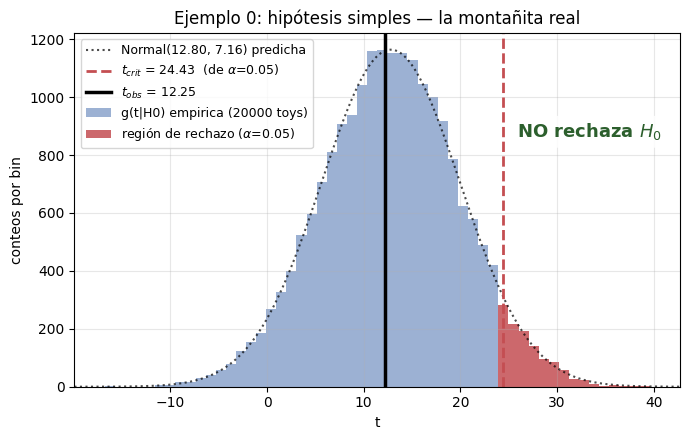

In [2]:
sigma = 1.0
n0 = 20
mu1 = 0.8  # H1: mu = 0.8 (hipotesis simple, valor fijo)
alpha0 = 0.05


def t_stat_simple(data, mu1, sigma):
    n = len(data)
    xbar = np.mean(data)
    return n * mu1**2 / sigma**2 - 2 * n * mu1 / sigma**2 * xbar


# "datos reales" (un solo dataset, para tener un t_obs)
mu_true_world0 = 0.05  # el mundo real tiene una mu chiquita, casi 0
data_real0 = rng.normal(loc=mu_true_world0, scale=sigma, size=n0)
t_obs0 = t_stat_simple(data_real0, mu1, sigma)
print(f"t_obs = {t_obs0:.4f}")

# toys bajo H0 (mu=0)
n_toys0 = 20000
toys0 = rng.normal(loc=0.0, scale=sigma, size=(n_toys0, n0))
t_toys0 = n0 * mu1**2 / sigma**2 - 2 * n0 * mu1 / sigma**2 * toys0.mean(axis=1)

# prediccion analitica exacta (sin toys) de la Normal de g(t|H0)
mu_pred0 = n0 * mu1**2 / sigma**2
sigma_pred0 = abs(2 * n0 * mu1 / sigma**2) * sigma / np.sqrt(n0)

p_toys0 = p_value_from_toys(t_obs0, t_toys0)
p_normal0 = stats.norm.sf(t_obs0, loc=mu_pred0, scale=sigma_pred0)
print(f"p-valor (toys)   = {p_toys0:.4f}")
print(f"p-valor (normal, exacto) = {p_normal0:.4f}")

plot_g_vs_normal(t_toys0, mu_pred0, sigma_pred0, t_obs=t_obs0, alpha=alpha0,
                  title="Ejemplo 0: hipótesis simples — la montañita real")

### Nota importante: la forma de $\chi^2_k$ depende fuertemente de $k$

El Ejemplo 0 formó una montaña porque $t$ resultó ser, exactamente, una variable Normal — no una $\chi^2$. A partir de aquí se trabaja con hipótesis **compuestas** ($H_1$ con un parámetro libre), y ahí $g(t|H_0)$ tiende a una $\chi^2_k$ por Wilks. Es natural esperar que la $\chi^2_k$ también forme una "montaña", pero eso **sólo** ocurre para $k\ge 3$ — **no** para $k=1$ o $k=2$, que son, precisamente, los casos más comunes en los ejemplos siguientes (un solo parámetro extra entre $H_0$ y $H_1$). La densidad de $\chi^2_k$ es:

$$ f(t;k) = \frac{1}{2^{k/2}\,\Gamma(k/2)}\; t^{\,k/2-1}\, e^{-t/2} $$

- **$k=1$**: diverge cuando $t\to 0^+$ (como $t^{-1/2}$) y decae después monótonamente — se ve como una curva tipo potencia/exponencial, **sin** pico interior.
- **$k=2$**: es exactamente una exponencial, $f(t;2)=\tfrac12 e^{-t/2}$ — también decae monótonamente desde $t=0$.
- **$k\ge 3$**: aparece un modo interior en $t=k-2$ — ahí sí se forma la "montaña" con pico lejos de cero.

Por eso en los Ejemplos 1, 2 y 4 que siguen (todos con $k=1$) el histograma de $g(t|H_0)$ se ve como una curva decreciente y no como una montaña: es exactamente lo que predice la teoría, no un error del código.

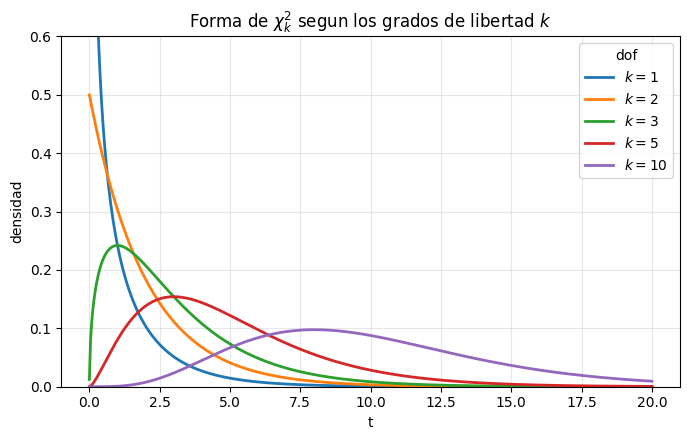

k=1 y k=2: decrecientes desde t=0 (sin pico interior).
k>=3: aparece un pico interior en t=k-2 -> forma de 'montaña'.


In [3]:
fig, ax = plt.subplots()
xs = np.linspace(1e-3, 20, 500)
for k in [1, 2, 3, 5, 10]:
    ax.plot(xs, stats.chi2.pdf(xs, df=k), lw=2, label=fr"$k={k}$")
ax.set_xlabel("t")
ax.set_ylabel("densidad")
ax.set_title(r"Forma de $\chi^2_k$ segun los grados de libertad $k$")
ax.set_ylim(0, 0.6)
ax.legend(title="dof")
plt.tight_layout()
plt.show()
print("k=1 y k=2: decrecientes desde t=0 (sin pico interior).")
print("k>=3: aparece un pico interior en t=k-2 -> forma de 'montaña'.")

## 6. Ejemplo 1 (chi2 exacta): media de una Gaussiana, $\sigma$ conocida

$H_0$: los datos $x_i \sim \mathcal{N}(0, \sigma^2)$ (media fija en 0).
$H_1$: los datos $x_i \sim \mathcal{N}(\mu, \sigma^2)$ con $\mu$ libre (1 parámetro extra $\Rightarrow k=1$).

### Derivación explícita

A diferencia del Ejemplo 0, aquí $H_1$ es una hipótesis **compuesta**: $\mu$ no está fijo, hay que estimarlo. Con $\sigma$ conocida, el MLE de $\mu$ es $\hat\mu=\bar x$ (maximiza la log-verosimilitud gaussiana). Partiendo otra vez de

$$ \ln L(x|\mu) = -\frac{n}{2}\ln(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_i (x_i-\mu)^2 $$

se evalúa en $\mu=0$ (para $H_0$) y en $\mu=\hat\mu=\bar x$ (para $H_1$, ya maximizada). El término $-\tfrac n2\ln(2\pi\sigma^2)$ vuelve a cancelarse al restar:

$$ t = -2\big[\ln L(0) - \ln L(\bar x)\big] = \frac{1}{\sigma^2}\left[\sum_i x_i^2 - \sum_i (x_i-\bar x)^2\right] $$

Para simplificar el corchete se usa la identidad de suma de cuadrados (la misma que está detrás de la descomposición varianza-total = varianza-dentro + varianza-entre en ANOVA): sumando y restando $\bar x$ dentro del primer término,

$$ \sum_i x_i^2 = \sum_i (x_i-\bar x+\bar x)^2 = \sum_i (x_i-\bar x)^2 + 2\bar x\underbrace{\sum_i (x_i-\bar x)}_{=\,0} + n\bar x^2 = \sum_i (x_i-\bar x)^2 + n\bar x^2 $$

(el término cruzado se anula porque $\sum_i(x_i-\bar x)=0$ por definición de $\bar x$). Sustituyendo:

$$ \sum_i x_i^2 - \sum_i (x_i-\bar x)^2 = n\bar x^2 $$

y por lo tanto:

$$ \boxed{\; t = \frac{n\,\bar x^2}{\sigma^2} = \left(\frac{\bar x}{\sigma/\sqrt n}\right)^{\!2} \;} $$

Como $\bar x\sim\mathcal N(0,\sigma^2/n)$ exactamente bajo $H_0$ (para cualquier $n$, dato gaussiano), la cantidad $Z=\bar x/(\sigma/\sqrt n)$ es exactamente $\mathcal N(0,1)$ — y $t=Z^2$ es, por *definición*, una $\chi^2_1$ (la $\chi^2$ con 1 grado de libertad es, precisamente, la distribución del cuadrado de una Normal estándar). No hace falta invocar Wilks ni ningún argumento asintótico: sale exacto, para cualquier $n$, de la estructura cuadrática de la verosimilitud gaussiana.

**Por qué este caso es "más exacto" que el caso general de Wilks:** la demostración general del teorema de Wilks (Sección 3) usa una expansión de Taylor de $\ln L$ alrededor del MLE, que en general **trunca** términos de orden superior — de ahí que el resultado sea solo asintótico. Aquí, como $\ln L(\mu)$ es **exactamente cuadrática** en $\mu$ (no hay términos de orden 3 o más), esa expansión de Taylor no trunca nada: es una igualdad exacta para cualquier $n$, no una aproximación. Por eso este ejemplo sirve como el caso "de libro" más limpio para verificar que el pipeline de toys efectivamente reproduce la $\chi^2_1$ — antes de pasar a casos donde Wilks sí es solo una aproximación asintótica.

t_obs = 1.5443
p-valor (toys)      = 0.2080
p-valor (chi2_1)    = 0.2140   <- deberian coincidir muy de cerca
t_critico (toys, alpha=0.05)  = 3.7478
t_critico (chi2_1, alpha=0.05) = 3.8415   <- chi2.ppf(1-alpha, df=1)


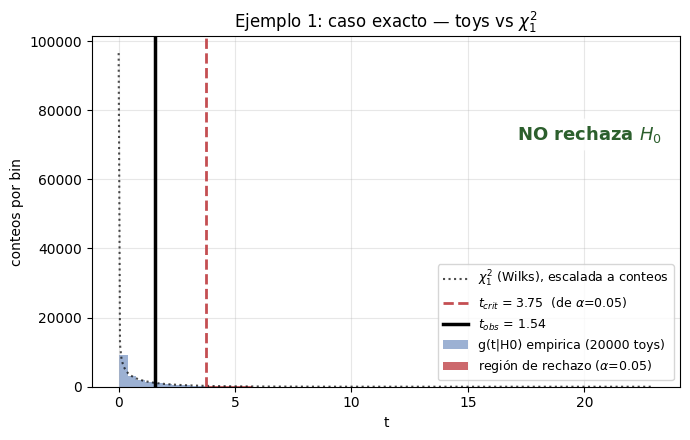

In [4]:
# --- "datos reales" (simulados una sola vez, para tener un t_obs) ---
sigma = 1.0
n = 30
mu_true_world = 0.15  # el "mundo real" tiene un mu chiquito (no exactamente 0)

data_real = rng.normal(loc=mu_true_world, scale=sigma, size=n)


def t_stat_known_sigma(data, sigma):
    xbar = np.mean(data)
    return len(data) * xbar**2 / sigma**2


t_obs = t_stat_known_sigma(data_real, sigma)
print(f"t_obs = {t_obs:.4f}")

# --- toys bajo H0: mu=0 fijo ---
n_toys = 20000
toys = rng.normal(loc=0.0, scale=sigma, size=(n_toys, n))
t_toys = n * toys.mean(axis=1)**2 / sigma**2

p_toys = p_value_from_toys(t_obs, t_toys)
p_chi2 = stats.chi2.sf(t_obs, df=1)

print(f"p-valor (toys)      = {p_toys:.4f}")
print(f"p-valor (chi2_1)    = {p_chi2:.4f}   <- deberian coincidir muy de cerca")

alpha = 0.05
tcrit_toys = t_crit_from_toys(t_toys, alpha)
tcrit_chi2 = stats.chi2.ppf(1 - alpha, df=1)
print(f"t_critico (toys, alpha=0.05)  = {tcrit_toys:.4f}")
print(f"t_critico (chi2_1, alpha=0.05) = {tcrit_chi2:.4f}   <- chi2.ppf(1-alpha, df=1)")

plot_g_vs_chi2(t_toys, dof=1, t_obs=t_obs,
               title="Ejemplo 1: caso exacto — toys vs $\\chi^2_1$")

## 7. Ejemplo 2: selección de orden de un modelo anidado

Este es el análogo directo de la selección de grado de un polinomio (p. ej. de Bernstein) por *forward selection* con LRT — aquí con una regresión polinomial simple y ruido gaussiano (en vez de NLL binomial), para que sea rápido y transparente. La mecánica es idéntica.

$H_0$: $y = P_n(x) + \varepsilon$ (polinomio de grado $n$)
$H_1$: $y = P_{n+1}(x) + \varepsilon$ (un coeficiente libre más, $k=1$)

Para Gaussianas con $\sigma$ estimada por MLE junto con los coeficientes, hay una fórmula cerrada muy útil (ajuste por mínimos cuadrados = MLE gaussiano):

$$ t = n_{datos}\,\ln\!\left(\frac{RSS_0}{RSS_1}\right) $$

donde $RSS$ es la suma de residuos al cuadrado de cada ajuste. Esta $t$ es la misma construcción $-2\ln(L_0/L_1)$, solo que reescrita en términos de $RSS$ (ejercicio algebraico estándar de la verosimilitud gaussiana concentrada).

t_obs (grado 2 vs 3) = 0.1523
p-valor (toys) = 0.7041   |   p-valor (chi2_1) = 0.6964


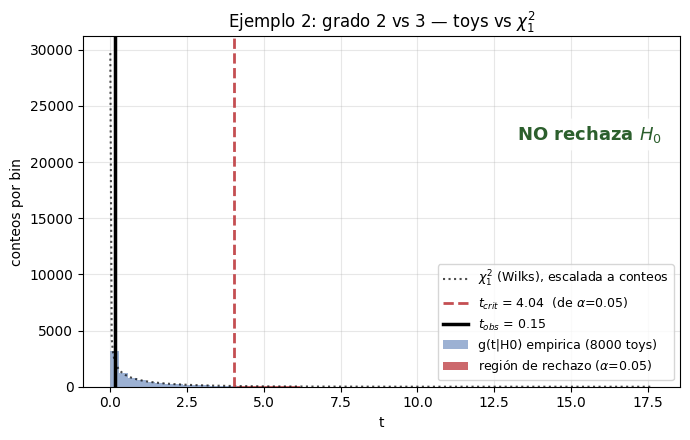


-> Sin boundary effects y con suficiente estadistica, toys y chi2 coinciden bien:
   esto es exactamente lo que se usa (implicitamente) en un forward selection por LRT.


In [5]:
def rss_for_degree(x, y, degree):
    coeffs = np.polyfit(x, y, degree)
    pred = np.polyval(coeffs, x)
    return np.sum((y - pred)**2), coeffs


def lrt_poly(x, y, deg0, deg1):
    rss0, coeffs0 = rss_for_degree(x, y, deg0)
    rss1, coeffs1 = rss_for_degree(x, y, deg1)
    t = len(x) * np.log(rss0 / rss1)
    return t, coeffs0, coeffs1


# --- "datos reales": el mundo real es EXACTAMENTE un polinomio de grado 2 + ruido ---
n_pts = 80
sigma_y = 0.35
x_data = np.linspace(-1, 1, n_pts)
true_coeffs = [0.9, 0.0, -0.4]  # grado 2: 0.9 x^2 - 0.4
y_data = np.polyval(true_coeffs, x_data) + rng.normal(0, sigma_y, n_pts)

deg0, deg1 = 2, 3  # H0: grado 2 (correcto) vs H1: grado 3 (un termino de mas)
t_obs, c0, c1 = lrt_poly(x_data, y_data, deg0, deg1)
print(f"t_obs (grado {deg0} vs {deg1}) = {t_obs:.4f}")

# --- toys bajo H0: genero datos desde el modelo de grado deg0 con los coefs ajustados ---
n_toys = 8000
t_toys_poly = np.empty(n_toys)
for i in range(n_toys):
    y_toy = np.polyval(c0, x_data) + rng.normal(0, sigma_y, n_pts)
    t_toys_poly[i], _, _ = lrt_poly(x_data, y_toy, deg0, deg1)

p_toys = p_value_from_toys(t_obs, t_toys_poly)
p_chi2 = stats.chi2.sf(t_obs, df=1)
print(f"p-valor (toys) = {p_toys:.4f}   |   p-valor (chi2_1) = {p_chi2:.4f}")

plot_g_vs_chi2(t_toys_poly, dof=1, t_obs=t_obs,
               title=f"Ejemplo 2: grado {deg0} vs {deg1} — toys vs $\\chi^2_1$")
print("\n-> Sin boundary effects y con suficiente estadistica, toys y chi2 coinciden bien:")
print("   esto es exactamente lo que se usa (implicitamente) en un forward selection por LRT.")

## 8. Ejemplo 3: cuando Wilks falla — parámetro en la frontera

Este es un caso relevante cuando se usan coeficientes (p. ej. de Bernstein) con restricción de positividad: si el parámetro extra de $H_1$ está **restringido** (ej. $\beta_1 \ge 0$, para garantizar una eficiencia no-negativa) y su valor verdadero bajo $H_0$ está justo en $\beta_1=0$ (la frontera), la $\chi^2_1$ pura **ya no es correcta**.

$H_0$: $y = \beta_0 + \varepsilon$
$H_1$: $y = \beta_0 + \beta_1 x^2 + \varepsilon$, con la restricción física $\beta_1 \ge 0$

Bajo $H_0$, el estimador *sin restricción* de $\beta_1$ es positivo o negativo con igual probabilidad ($\sim$50/50 por simetría). Cuando sale negativo, la restricción $\beta_1\ge 0$ lo "aplasta" a 0 — y entonces el ajuste restringido de $H_1$ coincide exactamente con $H_0$, dando $t=0$. Esto produce una masa puntual en $t=0$ con probabilidad $\approx 0.5$, y para $t>0$ la forma es la mitad de una $\chi^2_1$. Este es el resultado clásico de **Chernoff (1954)**, generalizado por **Self & Liang (1987)** para casos con más parámetros:

$$ g(t|H_0) = \tfrac{1}{2}\delta(t) + \tfrac{1}{2}\chi^2_1(t) $$

y el p-valor correcto es $p = \tfrac{1}{2}\,P(\chi^2_1 \ge t_{obs})$ — **la mitad** de lo que da la fórmula ingenua $P(\chi^2_1\ge t_{obs})$.

Fraccion de toys con t=0 (beta1_hat cayo en la frontera): 0.501
(la prediccion teorica de Chernoff es 0.5)
t_obs= 1.00  |  p ingenuo (chi2_1)=0.3173  |  p correcto (formula)=0.1587  |  p correcto (toys)=0.1633
t_obs= 2.71  |  p ingenuo (chi2_1)=0.0997  |  p correcto (formula)=0.0499  |  p correcto (toys)=0.0532
t_obs= 3.84  |  p ingenuo (chi2_1)=0.0500  |  p correcto (formula)=0.0250  |  p correcto (toys)=0.0291
t_obs= 6.00  |  p ingenuo (chi2_1)=0.0143  |  p correcto (formula)=0.0072  |  p correcto (toys)=0.0089


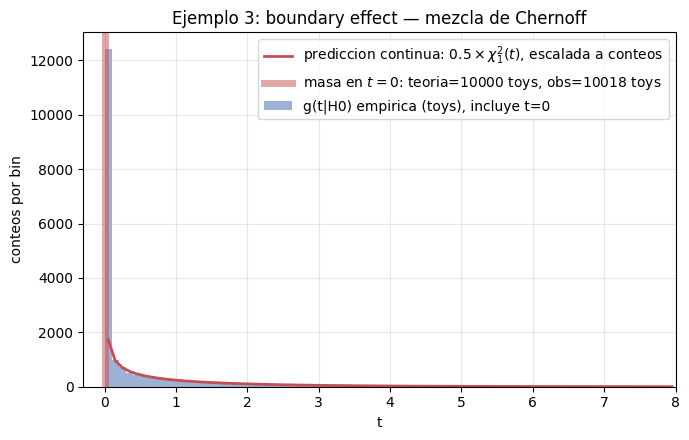


-> Si los coeficientes (p. ej. de Bernstein) tienen restriccion de positividad y el termino
   que agregas en cada paso del forward selection puede caer en esa frontera bajo H0,
   usar chi2_1 pura sin corregir hace el test MAS CONSERVADOR de lo necesario
   (p-valor ingenuo = 2x el p-valor correcto).


In [6]:
def lrt_poly_boundary(x, y, deg0=0):
    # H0: solo beta0 (constante)
    beta0_hat = np.mean(y)
    rss0 = np.sum((y - beta0_hat)**2)

    # H1 sin restriccion: y = b0 + b1*x^2
    X = np.column_stack([np.ones_like(x), x**2])
    coeffs, *_ = np.linalg.lstsq(X, y, rcond=None)
    b0_unc, b1_unc = coeffs

    if b1_unc < 0:
        # la restriccion beta1>=0 lo manda a 0 -> H1 restringido == H0
        rss1 = rss0
    else:
        pred = X @ coeffs
        rss1 = np.sum((y - pred)**2)

    if rss1 >= rss0:  # por numerica, evita log de <1
        return 0.0, b1_unc
    t = len(x) * np.log(rss0 / rss1)
    return t, b1_unc


n_pts = 60
sigma_y = 0.4
x_data2 = np.linspace(-1, 1, n_pts)

n_toys = 20000
t_toys_bnd = np.empty(n_toys)
for i in range(n_toys):
    y_toy = 0.5 + rng.normal(0, sigma_y, n_pts)   # H0 real: beta1=0
    t_toys_bnd[i], _ = lrt_poly_boundary(x_data2, y_toy)

frac_zero = np.mean(t_toys_bnd == 0)
print(f"Fraccion de toys con t=0 (beta1_hat cayo en la frontera): {frac_zero:.3f}")
print("(la prediccion teorica de Chernoff es 0.5)")

# comparacion de p-valores para un t_obs de ejemplo
for t_obs_example in [1.0, 2.71, 3.84, 6.0]:
    p_naive = stats.chi2.sf(t_obs_example, df=1)
    p_correct_toys = p_value_from_toys(t_obs_example, t_toys_bnd)
    p_correct_formula = 0.5 * stats.chi2.sf(t_obs_example, df=1)
    print(f"t_obs={t_obs_example:5.2f}  |  p ingenuo (chi2_1)={p_naive:.4f}"
          f"  |  p correcto (formula)={p_correct_formula:.4f}"
          f"  |  p correcto (toys)={p_correct_toys:.4f}")

fig, ax = plt.subplots()
xmax = 8.0
nbins = 80
counts, edges = np.histogram(t_toys_bnd, bins=nbins, range=(0, xmax))
bin_width = edges[1] - edges[0]
centers = 0.5 * (edges[:-1] + edges[1:])

ax.bar(centers, counts, width=bin_width, alpha=0.55, color="#4C72B0",
       label="g(t|H0) empirica (toys), incluye t=0")
predicted_counts = 0.5 * stats.chi2.pdf(np.clip(centers, 1e-6, None), df=1) * bin_width * n_toys
ax.plot(centers, predicted_counts, color="#C44E52", lw=2,
        label=r"prediccion continua: $0.5\times\chi^2_1(t)$, escalada a conteos")
n_zero_obs = int(round(frac_zero * n_toys))
ax.axvline(0, color="#C44E52", lw=5, alpha=0.5,
           label=fr"masa en $t=0$: teoria={0.5*n_toys:.0f} toys, obs={n_zero_obs} toys")
ax.set_xlabel("t"); ax.set_ylabel("conteos por bin")
ax.set_title("Ejemplo 3: boundary effect — mezcla de Chernoff")
ax.legend(); ax.set_xlim(-0.3, xmax)
plt.tight_layout(); plt.show()

print("\n-> Si los coeficientes (p. ej. de Bernstein) tienen restriccion de positividad y el termino")
print("   que agregas en cada paso del forward selection puede caer en esa frontera bajo H0,")
print("   usar chi2_1 pura sin corregir hace el test MAS CONSERVADOR de lo necesario")
print("   (p-valor ingenuo = 2x el p-valor correcto).")

## 9. Ejemplo 4: hipótesis no anidadas — Gaussiana vs. t-Student

Un caso clásico de hipótesis no anidadas. $H_0$: los datos vienen de una Gaussiana. $H_1$: vienen de una t-Student. Estrictamente, Gaussiana y t-Student *son* anidadas en el límite $\nu\to\infty$ — pero ese límite está en el infinito, no en un punto interior, así que Wilks no aplica de forma limpia (otro caso "frontera", ahora en el infinito). Aquí simplemente usamos **toys** — no hay atajo analítico razonable.

Pasos (igual que antes, ahora con dos modelos genuinamente distintos):
1. Con los datos reales, ajustas MLE de Gaussiana y de t-Student por separado → $t_{obs}$.
2. Para los toys, generas datos **desde la Gaussiana** (la que define $H_0$) usando los parámetros ajustados.
3. A cada toy le repites el mismo procedimiento (ajustas ambos modelos, calculas $t_{toy}$).
4. El histograma de $t_{toy}$ es la $g(t|H_0)$ empírica — y como se ve abajo, **no** coincide con una $\chi^2_1$ limpia.

t_obs = -0.0000
p-valor (toys, correcto)      = 0.8175
p-valor (chi2_1, NO confiable) = 1.0000


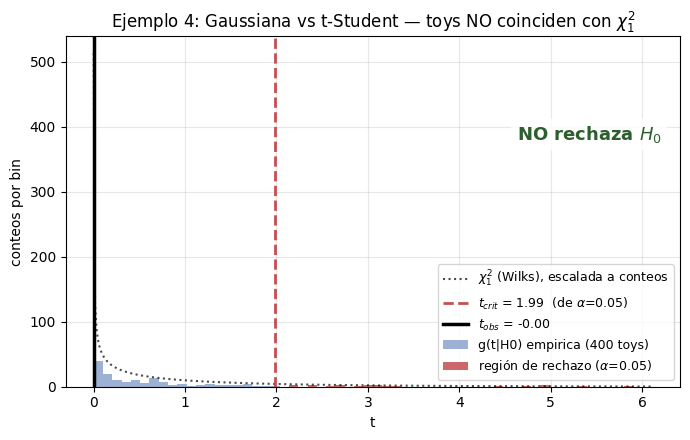


-> Fijate que aqui la chi2_1 (linea roja) ya NO describe bien el histograma de toys:
   es justo el caso de cambiar la forma de t: sin nested models limpios
   y sin condiciones de regularidad, Wilks deja de aplicar y SOLO los toys son confiables.


In [7]:
def nll_normal(params, data):
    mu, sigma = params
    if sigma <= 0:
        return np.inf
    return -np.sum(stats.norm.logpdf(data, loc=mu, scale=sigma))


def fit_normal(data):
    mu0, sigma0 = np.mean(data), np.std(data)
    return mu0, sigma0, -nll_normal((mu0, sigma0), data)


def fit_t_student(data):
    # scipy.stats.t.fit hace la MLE (nu, loc, scale) via optimizacion numerica
    nu, loc, scale = stats.t.fit(data)
    loglik = np.sum(stats.t.logpdf(data, nu, loc=loc, scale=scale))
    return nu, loc, scale, loglik


def t_stat_gauss_vs_t(data):
    _, _, loglik_gauss = fit_normal(data)
    _, _, _, loglik_t = fit_t_student(data)
    return -2 * (loglik_gauss - loglik_t)


# "datos reales": el mundo real SI es gaussiano (para poder juzgar si el test es razonable)
n4 = 120
data_real4 = rng.normal(loc=0.0, scale=1.0, size=n4)
t_obs4 = t_stat_gauss_vs_t(data_real4)
print(f"t_obs = {t_obs4:.4f}")

n_toys4 = 400  # el fit de t-Student es mas lento -> menos toys
t_toys4 = np.empty(n_toys4)
mu_h0, sigma_h0, _ = fit_normal(data_real4)
for i in range(n_toys4):
    toy = rng.normal(loc=mu_h0, scale=sigma_h0, size=n4)
    t_toys4[i] = t_stat_gauss_vs_t(toy)

p_toys4 = p_value_from_toys(t_obs4, t_toys4)
p_chi2_4 = stats.chi2.sf(t_obs4, df=1)  # "ingenuo" - NO deberia ser confiable aqui
print(f"p-valor (toys, correcto)      = {p_toys4:.4f}")
print(f"p-valor (chi2_1, NO confiable) = {p_chi2_4:.4f}")

plot_g_vs_chi2(t_toys4, dof=1, t_obs=t_obs4,
               title="Ejemplo 4: Gaussiana vs t-Student — toys NO coinciden con $\\chi^2_1$")
print("\n-> Fijate que aqui la chi2_1 (linea roja) ya NO describe bien el histograma de toys:")
print("   es justo el caso de cambiar la forma de t: sin nested models limpios")
print("   y sin condiciones de regularidad, Wilks deja de aplicar y SOLO los toys son confiables.")

## 10. Las "dos montañitas": $g(t|H_0)$, $g'(t|H_1)$, $\alpha$, $\beta$, potencia

Se retoma el caso simple-vs-simple ya visto en el Ejemplo 0 (donde Neyman–Pearson aplica exactamente), ahora agregando también los toys bajo $H_1$: $H_0$: $\mu=0$; $H_1$: $\mu=\mu_1$ fijo, $\sigma$ conocida. Se generan toys bajo **cada** hipótesis y se grafican ambos histogramas juntos — las "dos montañitas" de un ejercicio clásico de libro de texto. Con un $t_{crítico}$ fijado por $\alpha$, quedan marcadas visualmente las áreas de $\alpha$ y $\beta$.

alpha elegido         = 0.05
t_critico             = -1.031
beta (error tipo II)  = 0.027
potencia (1-beta)     = 0.973


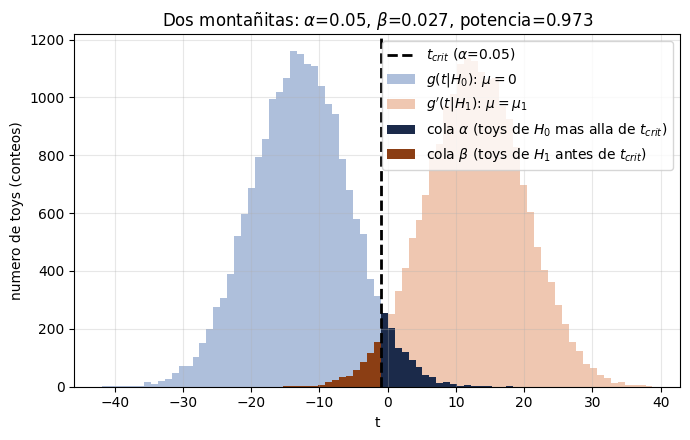

In [8]:
sigma = 1.0
n5 = 20
mu1 = 0.8   # H1: mu = 0.8 (hipotesis simple, valor fijo)
alpha = 0.05


def t_stat_simple_vs_simple(data, mu0, mu1, sigma):
    ll0 = np.sum(stats.norm.logpdf(data, loc=mu0, scale=sigma))
    ll1 = np.sum(stats.norm.logpdf(data, loc=mu1, scale=sigma))
    return -2 * (ll0 - ll1)


n_toys5 = 20000
toys_h0 = rng.normal(0.0, sigma, size=(n_toys5, n5))
toys_h1 = rng.normal(mu1, sigma, size=(n_toys5, n5))

t_h0 = np.array([t_stat_simple_vs_simple(d, 0.0, mu1, sigma) for d in toys_h0])
t_h1 = np.array([t_stat_simple_vs_simple(d, 0.0, mu1, sigma) for d in toys_h1])

t_crit = t_crit_from_toys(t_h0, alpha)
beta = np.mean(t_h1 < t_crit)
power = 1 - beta

print(f"alpha elegido         = {alpha}")
print(f"t_critico             = {t_crit:.3f}")
print(f"beta (error tipo II)  = {beta:.3f}")
print(f"potencia (1-beta)     = {power:.3f}")

fig, ax = plt.subplots()
bins = np.linspace(min(t_h0.min(), t_h1.min()), max(t_h0.max(), t_h1.max()), 80)
counts_h0, edges = np.histogram(t_h0, bins=bins)
counts_h1, _ = np.histogram(t_h1, bins=edges)
centers = 0.5 * (edges[:-1] + edges[1:])
width = edges[1] - edges[0]

ax.bar(centers, counts_h0, width=width, alpha=0.45, color="#4C72B0", label=r"$g(t|H_0)$: $\mu=0$")
ax.bar(centers, counts_h1, width=width, alpha=0.45, color="#DD8452", label=r"$g'(t|H_1)$: $\mu=\mu_1$")

# resaltar, con el mismo histograma (sin suavizar), las colas que definen alpha y beta
mask_alpha = centers >= t_crit
mask_beta = centers < t_crit
ax.bar(centers[mask_alpha], counts_h0[mask_alpha], width=width, color="#1B2A4A",
       label=r"cola $\alpha$ (toys de $H_0$ mas alla de $t_{crit}$)")
ax.bar(centers[mask_beta], counts_h1[mask_beta], width=width, color="#8B3E14",
       label=r"cola $\beta$ (toys de $H_1$ antes de $t_{crit}$)")

ax.axvline(t_crit, color="k", ls="--", lw=2, label=fr"$t_{{crit}}$ ($\alpha$={alpha})")
ax.set_xlabel("t"); ax.set_ylabel("numero de toys (conteos)")
ax.set_title(f"Dos montañitas: $\\alpha$={alpha}, $\\beta$={beta:.3f}, potencia={power:.3f}")
ax.legend()
plt.tight_layout(); plt.show()

## 11. Ejercicios (de fácil a difícil)

Usa las funciones y el código de las secciones anteriores como punto de partida.

**1. Fácil — variar $\alpha$.**
En el Ejemplo 1, recalcula $t_{crítico}$ (con toys y con `chi2.ppf`) para $\alpha=0.01$ y $\alpha=0.10$. Grafica cómo cambia $t_{crítico}$ en función de $\alpha$ (barre $\alpha$ de 0.001 a 0.5) y compara ambas curvas en un mismo plot.

**2. Fácil-medio — $\sigma$ desconocida.**
Repite el Ejemplo 1 pero ahora estimando $\sigma$ también por MLE en ambos modelos ($H_0$: $\mu=0$, $\sigma$ libre; $H_1$: $\mu$ y $\sigma$ libres). ¿Sigue $t\sim\chi^2_1$ exactamente, o solo asintóticamente? Genera toys con $n=10$ (muestra chica) y $n=200$ (muestra grande) y compara qué tan bien coincide cada caso con la $\chi^2_1$.

**3. Medio — grados de libertad.**
En el Ejemplo 2, compara directamente grado $n=2$ contra $n=5$ (tres coeficientes extra, $k=3$) en vez de $n=2$ vs $n=3$. Verifica que el histograma de toys ahora coincide con $\chi^2_3$ y no con $\chi^2_1$ — y, a diferencia de los ejemplos anteriores, ya debería verse el pico interior ("montaña") que se explicó antes.

**4. Medio-difícil — mezcla con 2 parámetros extra.**
Extiende el Ejemplo 3 a un caso con **dos** parámetros extra donde solo **uno** tiene restricción de positividad (el otro es libre). Investiga (o deriva, o busca en Self & Liang 1987) qué mezcla de $\chi^2_0,\chi^2_1,\chi^2_2$ resulta, y verifícalo con toys.

**5. Difícil — curva de potencia.**
Para el Ejemplo 4 (Gaussiana vs. t-Student), en vez de un solo $n$, calcula la potencia del test (a $\alpha=0.05$, usando $t_{crítico}$ de los toys bajo $H_0$) en función del tamaño de muestra $n$, generando toys bajo $H_1$ real (datos que sí vienen de una t-Student con $\nu$ chico, digamos $\nu=3$). Grafica potencia vs. $n$ y encuentra aproximadamente cuántos datos necesitas para una potencia del 80%.

**6. Difícil / aplicado — un caso real de análisis.**
Adapta el pipeline de toys de este notebook (Ejemplo 2 + Ejemplo 3) a una selección real de grado de un polinomio de Bernstein: usa una NLL binomial en vez de la Gaussiana, y agrega la restricción de positividad de los coeficientes. Corre un puñado de toys bajo $H_0$ (el grado elegido por el forward selection) y compara el histograma resultante contra la $\chi^2_1$ pura que se haya usado habitualmente — ¿hay evidencia de boundary effect?

## Referencias

- S. S. Wilks, *"The Large-Sample Distribution of the Likelihood Ratio for Testing Composite Hypotheses"*, Ann. Math. Statist. 9 (1938) 60.
- J. Neyman, E. S. Pearson, *"On the Problem of the Most Efficient Tests of Statistical Hypotheses"*, Phil. Trans. R. Soc. A 231 (1933) 289.
- H. Chernoff, *"On the Distribution of the Likelihood Ratio"*, Ann. Math. Statist. 25 (1954) 573.
- S. Self, K.-Y. Liang, *"Asymptotic Properties of Maximum Likelihood Estimators and Likelihood Ratio Tests under Nonstandard Conditions"*, JASA 82 (1987) 605.
- G. Cowan, K. Cranmer, E. Gross, O. Vitells, *"Asymptotic formulae for likelihood-based tests of new physics"*, Eur. Phys. J. C 71 (2011) 1554, [arXiv:1007.1727](https://arxiv.org/abs/1007.1727).
- T. Junk, *"Confidence Level Computation for Combining Searches with Small Statistics"*, NIM A 434 (1999) 435, [hep-ex/9902006](https://arxiv.org/abs/hep-ex/9902006).
- A. L. Read, *"Presentation of search results: the $CL_s$ technique"*, J. Phys. G 28 (2002) 2693.